# 01. Сбор и подготовка датасета для классификатора документов

**Задача классификатора** — определить **тип (жанр) документа**, а не его тему.
Финансовый анализ текста (тональность, сущности) делают отдельные модули системы.

| Класс | Что это за документ | Источник |
|---|---|---|
| Financial | официальная финансовая отчётность компаний (годовые отчёты 10-K) | `c3po-ai/edgar-corpus` |
| Legal | юридические документы: пункты договоров | `coastalcph/lex_glue` (`ledgar`) |
| Scientific | научные статьи (аннотации) | `gfissore/arxiv-abstracts-2021` |
| News | новостные статьи на любую тему, включая экономику | `abisee/cnn_dailymail` |
| Technical | техническая документация, вопросы и ответы по ПО | `HuggingFaceGECLM/StackExchange_Mar2023` |
| General | энциклопедические статьи | `wikimedia/wikipedia` |

**Результат ноутбука:** файл `data/processed/dataset.parquet` — по 2000 текстов на класс,
колонки `text`, `label`, `source`, `doc_id`.

Подробное обоснование всех решений — в `docs/data.md`.

**Порядок:**
0. Настройки
1. Разведка: почему отказались от AG News и DBpedia
2. Функции очистки
3. Сбор по классам
4. Объединение, балансировка, проверка
5. Сохранение

## 0. Настройки

Все «магические числа» собраны в одном месте. Если захочется поменять размер выборки
или длину текстов — меняем здесь, а не по всему ноутбуку.

- `SEED` — фиксированное зерно случайности: при повторном запуске получится **тот же самый** датасет (воспроизводимость).
- `N_PER_CLASS` — сколько текстов берём в каждый класс (одинаково для всех → баланс классов).
- `MIN_WORDS` / `MAX_WORDS` — окно длины текста в словах (почему именно так — см. раздел 2).
- `RAW_PER_SOURCE` — сколько сырых документов скачиваем из каждого источника (с запасом: часть отсеется при очистке).

In [1]:
import re
import unicodedata
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from datasets import load_dataset

# huggingface_hub warns about symlinks on Windows — harmless, hide it
warnings.filterwarnings("ignore", message=".*symlinks.*")

SEED = 42
N_PER_CLASS = 2000
MIN_WORDS = 60
MAX_WORDS = 120
MAX_START_WORD = (
    1000  # windows start no deeper than this word (tails hold references, signatures)
)
RAW_PER_SOURCE = 3000


def find_project_root() -> Path:
    # Walk up from the current folder until we find pyproject.toml,
    # so the notebook works no matter where it is launched from.
    path = Path.cwd().resolve()
    for candidate in [path, *path.parents]:
        if (candidate / "pyproject.toml").exists():
            return candidate
    raise FileNotFoundError("pyproject.toml not found")


ROOT = find_project_root()
OUT_PATH = ROOT / "data" / "processed" / "dataset.parquet"


def word_stats(texts: pd.Series) -> pd.Series:
    # Length of each text in words -> summary statistics (count, mean, quartiles)
    return texts.str.split().str.len().describe().round(1)


print("Project root:", ROOT)

Project root: D:\FinSight


## 1. Разведка: почему отказались от AG News и DBpedia

Перед обучением модели **надо смотреть на данные**. Две «очевидные» кандидатуры оказались непригодны
по одной и той же причине — **слишком короткие тексты**.

Если в одном классе тексты по 40 слов, а в другом по 500, модель выучит простое правило
«короткий текст → класс X» и будет классифицировать по длине, а не по смыслу.
Это называется **утечка признака (leakage)**: на тесте всё отлично, а на реальных документах — ошибки.

In [2]:
# AG News: 120k news items, labels 0=World 1=Sports 2=Business 3=Sci/Tech
ag_news = load_dataset("fancyzhx/ag_news", split="train").to_pandas()
print(ag_news["text"].iloc[0])
word_stats(ag_news["text"])

Wall St. Bears Claw Back Into the Black (Reuters) Reuters - Short-sellers, Wall Street's dwindling\band of ultra-cynics, are seeing green again.


count    120000.0
mean         37.8
std          10.1
min           8.0
25%          32.0
50%          37.0
75%          43.0
max         177.0
Name: text, dtype: float64

**Вывод по AG News:** в среднем ~38 слов — это заголовок + одно предложение анонса, а не статья.
Длиннее 50 слов только ~8% текстов. Плюс мусор: `(Reuters) Reuters -` в начале, `\\` в тексте.
Пример выше к тому же из класса Business (`label=2`), который пересекается с нашим Financial.

**Замена:** `abisee/cnn_dailymail` — полные статьи CNN (медиана ~550 слов).

In [3]:
# DBpedia: short Wikipedia abstracts (candidate for the General class)
dbpedia = load_dataset("fancyzhx/dbpedia_14", split="train").to_pandas()
word_stats(dbpedia["content"].sample(3000, random_state=SEED))

count    3000.0
mean       46.3
std        22.7
min         5.0
25%        26.0
50%        47.0
75%        66.0
max       211.0
Name: content, dtype: float64

**Вывод по DBpedia:** медиана ~46 слов — та же проблема, что у AG News.

**Замена:** `wikimedia/wikipedia` — полные статьи Википедии (медиана ~2300 слов),
из которых мы вырезаем фрагмент нужной длины.

### Проверка: много ли финансовых новостей среди новостей CNN?

Опасение: если в классе News много чисто финансовых статей, они будут «спорить» с классом Financial.
Ищем по ключевым словам и смотрим долю.

In [4]:
cnn_sample = pd.DataFrame(
    list(
        load_dataset(
            "abisee/cnn_dailymail", "3.0.0", split="train", streaming=True
        ).take(RAW_PER_SOURCE)
    )
)
finance_words = "stock market|Wall Street|shares|earnings|investors|Dow Jones"
is_finance = cnn_sample["article"].str.contains(finance_words, case=False)
print(f"Articles with finance keywords: {is_finance.sum()} ({is_finance.mean():.1%})")

Articles with finance keywords: 127 (4.2%)


**Вывод:** ~4% статей содержат финансовые слова, и при ручном просмотре примерно половина из них —
политика или спорт (слово «investors» просто мелькнуло). Так как классификатор определяет
**тип** документа, финансовая новость — это всё равно **News**. Ничего не удаляем.
Класс Financial — это отчёты 10-K, по стилю они сильно отличаются от новостей.

## 2. Функции очистки

### Общая очистка — `normalize`
Применяется ко **всем** классам одинаково:
- **Unicode NFKC** — приводит «экзотические» символы к обычным (например, неразрывный пробел `\xa0` → пробел);
- **удаление ссылок** (`http://...`) — они есть в одних источниках и нет в других, модель могла бы выучить «ссылка → Technical»;
- **схлопывание пробелов и переносов строк** — в arXiv жёсткие переносы строк, в Википедии абзацы,
  в Stack Exchange — код. Форматирование не должно быть признаком класса.

> Эту же функцию потом нужно применять к документам пользователя в приложении перед классификацией —
> модель должна видеть тексты в том же виде, в каком училась.

### Окно длины — `take_window`
Главная идея против утечки по длине: **из каждого документа вырезаем фрагмент случайной длины от 60 до 120 слов**.
- Длинные документы (новости, отчёты, Википедия) режутся до этого окна.
- Короткие (аннотации arXiv ~110 слов, пункты договоров ~85 слов) почти целиком попадают в тот же диапазон.
- Тексты короче 60 слов выбрасываем.

В итоге длины всех классов лежат в одном диапазоне, и по длине класс не угадать.

Почему **60–120 слов**: верхняя граница ограничена самыми короткими классами (arXiv, Legal) — их «удлинить» нельзя.
Для трансформера 120 слов ≈ 160 токенов — модель учится быстро даже на ноутбучной видеокарте.
Длинный документ в приложении будем классифицировать по нескольким таким фрагментам и усреднять ответ.

Ещё две тонкости:
- **Начало фрагмента — всегда с начала предложения**, конец — по возможности на конце предложения.
  Иначе у длинных классов текст начинался бы с середины фразы, а у коротких — нет, и модель выучила бы и это.
- **Фрагмент берём не глубже 1000-го слова**: в конце документов — списки литературы, категории Википедии, подписи.

In [5]:
URL_RE = re.compile(
    r"https?://\s?\S+|www\.\S+"
)  # "http:// site.org" (with a space) also occurs
SENTENCE_END = (".", "!", "?", '."', '?"', '!"', ".\u201d", "?\u201d")


def normalize(text: str) -> str:
    """Common cleaning for every class: unicode, URLs, whitespace."""
    text = unicodedata.normalize("NFKC", text)
    text = URL_RE.sub(" ", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()


def take_window(text: str, rng: np.random.Generator) -> str | None:
    """Cut a fragment of MIN_WORDS..MAX_WORDS words that starts at a sentence start.

    Returns None if the text is too short.
    """
    words = text.split()
    target_len = int(rng.integers(MIN_WORDS, MAX_WORDS + 1))

    # Candidate starts: the very beginning or the word right after a sentence end
    starts = [0] + [
        i + 1 for i, w in enumerate(words[:MAX_START_WORD]) if w.endswith(SENTENCE_END)
    ]
    starts = [s for s in starts if len(words) - s >= MIN_WORDS]
    if not starts:
        return None

    start = int(rng.choice(starts))
    window = words[start : start + target_len]

    # Trim the tail back to the last sentence end, if that keeps enough words
    ends = [
        i
        for i, w in enumerate(window)
        if w.endswith(SENTENCE_END) and i + 1 >= MIN_WORDS
    ]
    if ends:
        window = window[: ends[-1] + 1]

    return " ".join(window) if len(window) >= MIN_WORDS else None


# Quick self-check on a toy text
demo = " ".join(f"Sentence number {i} has five words." for i in range(40))
print(take_window(demo, np.random.default_rng(SEED)))

Sentence number 23 has five words. Sentence number 24 has five words. Sentence number 25 has five words. Sentence number 26 has five words. Sentence number 27 has five words. Sentence number 28 has five words. Sentence number 29 has five words. Sentence number 30 has five words. Sentence number 31 has five words. Sentence number 32 has five words.


### Очистка под каждый источник

У каждого источника свой специфический мусор. Его надо убрать, потому что он **однозначно выдаёт класс**:
модель запомнила бы «есть `(CNN) --` → News» вместо того, чтобы понимать текст.

| Источник | Что убираем | Пример |
|---|---|---|
| CNN | «шапку» с городом и агентством, ссылки на видео, служебные врезки и подписи | `WASHINGTON (CNN) --`, `Watch ... »`, `iReport.com: ...`, `E-mail to a friend` |
| Wikipedia | хвост статьи: «See also», «References», категории | `References\nNotes` |
| arXiv | LaTeX-формулы — в PDF пользователя их не будет в таком виде | `$\exp(-3N)$` |
| EDGAR 10-K | заголовки разделов отчёта | `ITEM 7. MANAGEMENT'S DISCUSSION...`, `Item 1A.` в конце |
| Stack Exchange | метки авторов реплик | `user1431:` |
| Ledgar | отдельной очистки не нужно (только общая `normalize`) | — |

Важно: специальная очистка делается **до** `normalize`, потому что многие шаблоны опираются на переносы строк.

In [6]:
# "WASHINGTON (CNN) -- " — usually at the start, sometimes after a photo caption
CNN_DATELINE_RE = re.compile(
    r"(?:[A-Z][A-Za-z.,' ]{0,60})?\([A-Za-z. ]{2,25}\)\s*--\s*"
)
CNN_TAIL_RE = re.compile(r"E-mail to a friend.*$", re.DOTALL)
CNN_CREDIT_RE = re.compile(r"CNN's [^.]{0,100}? contributed to this report\.?")
CNN_VIDEO_RE = re.compile(
    r"[^.!?»\n]*»\s*\.?"
)  # "Watch aerial footage of destruction » ."
CNN_IREPORT_RE = re.compile(
    r"iReport\.com:[^.!?\n]*[.!?]?"
)  # "iReport.com: Sound off on AIG ."


def clean_cnn(text: str) -> str:
    text = CNN_DATELINE_RE.sub("", text)
    text = CNN_TAIL_RE.sub("", text)
    text = CNN_CREDIT_RE.sub("", text)
    text = CNN_VIDEO_RE.sub(" ", text)
    return CNN_IREPORT_RE.sub(" ", text)


WIKI_TAIL_RE = re.compile(
    r"\n\s*(?:See also|References|External links|Notes|Further reading|Bibliography|Sources)\s*\n.*$",
    re.DOTALL,
)


def clean_wikipedia(text: str) -> str:
    return WIKI_TAIL_RE.sub("", text)


LATEX_MATH_RE = re.compile(r"\$[^$]*\$")


def clean_arxiv(text: str) -> str:
    return LATEX_MATH_RE.sub(" ", text)


EDGAR_ITEM_LINE_RE = re.compile(r"^\s*item\s*\d+[a-z]?\b", re.IGNORECASE)
EDGAR_ITEM_TAIL_RE = re.compile(r"\bitem\s*\d+[a-z]?\.?\s*$", re.IGNORECASE)


def clean_edgar(text: str) -> str:
    lines = text.strip().split("\n")
    # Drop the "Item 7." heading line ...
    if lines and EDGAR_ITEM_LINE_RE.match(lines[0]):
        lines = lines[1:]
    # ... and an ALL-CAPS title right after it ("MANAGEMENT'S DISCUSSION AND ANALYSIS ...")
    while lines and lines[0].strip() and lines[0].strip() == lines[0].strip().upper():
        lines = lines[1:]
    text = "\n".join(lines)
    return EDGAR_ITEM_TAIL_RE.sub(
        "", text
    )  # trailing "Item 1A." that starts the next section


SE_USER_RE = re.compile(r"(?m)^user\d+:\s*")


def clean_stackexchange(text: str) -> str:
    return SE_USER_RE.sub("", text)


print(
    clean_cnn(
        "WASHINGTON (CNN) -- The president said. Watch the speech » . He left. E-mail to a friend"
    )
)
print(clean_edgar("ITEM 7.\nMANAGEMENT'S DISCUSSION\nRevenue grew by 5%.\nItem 7A."))
print(clean_stackexchange("user42: How do I fix ssh?\n\nuser7: Edit sshd_config."))

The president said.  He left. 
Revenue grew by 5%.

How do I fix ssh?

Edit sshd_config.


### Общая функция сборки класса

Для каждого документа: специальная очистка → `normalize` → вырезать окно.
У каждого класса свой генератор случайных чисел (`SEED + номер`), чтобы результат одного класса
не зависел от того, сколько случайных чисел «потратил» предыдущий.

`doc_id` — идентификатор исходного документа. Из каждого документа берём **один** фрагмент,
поэтому части одного документа не попадут одновременно в обучающую и тестовую выборку
(иначе модель «видела бы ответы» заранее).

In [7]:
def build_class(
    raw: pd.DataFrame, label: str, source: str, cleaner, class_idx: int
) -> pd.DataFrame:
    """raw must have columns `text` and `doc_id`. Returns cleaned fragments for one class."""
    rng = np.random.default_rng(SEED + class_idx)
    rows = []
    for text, doc_id in zip(raw["text"], raw["doc_id"]):
        if not isinstance(text, str) or not text.strip():
            continue
        if cleaner is not None:
            text = cleaner(text)
        fragment = take_window(normalize(text), rng)
        if fragment is not None:
            rows.append(
                {
                    "text": fragment,
                    "label": label,
                    "source": source,
                    "doc_id": f"{source}:{doc_id}",
                }
            )

    result = pd.DataFrame(rows).drop_duplicates(subset="text")
    print(f"{label:<10} raw={len(raw):>5}  kept={len(result):>5}")
    return result


classes: dict[str, pd.DataFrame] = {}

## 3. Сбор по классам

Большие датасеты читаем со `streaming=True` и `.take(N)` — скачивается только нужный кусок, а не гигабайты.

### News — CNN
Статьи, которые начинаются с «Editor's note» (редакционная врезка вместо текста статьи), выбрасываем.

In [8]:
news_raw = cnn_sample.rename(columns={"article": "text", "id": "doc_id"})
news_raw = news_raw[~news_raw["text"].str.startswith("Editor's note")]

classes["News"] = build_class(news_raw, "News", "cnn_dailymail", clean_cnn, class_idx=0)
print(classes["News"]["text"].iloc[0])

News       raw= 2936  kept= 2932
"But I try very hard not to go that way because it would be too easy for them." His latest outing as the boy wizard in "Harry Potter and the Order of the Phoenix" is breaking records on both sides of the Atlantic and he will reprise the role in the last two films. There is life beyond Potter, however.


### General — Wikipedia
Английская Википедия, дамп от 01.11.2023. Статьи идут в порядке id, поэтому берём первые 3000 —
это ограничение (не случайная выборка), но тематика у них разная.

In [9]:
wiki_stream = load_dataset(
    "wikimedia/wikipedia", "20231101.en", split="train", streaming=True
)
wiki_raw = pd.DataFrame(list(wiki_stream.take(RAW_PER_SOURCE)))[["id", "text"]].rename(
    columns={"id": "doc_id"}
)

classes["General"] = build_class(
    wiki_raw, "General", "wikipedia", clean_wikipedia, class_idx=1
)
print(classes["General"]["text"].iloc[0])

Resolving data files:   0%|          | 0/41 [00:00<?, ?it/s]

General    raw= 3000  kept= 2934
It was after the institution of authority that anarchistic ideas were espoused as a reaction. The most notable precursors to anarchism in the ancient world were in China and Greece. In China, philosophical anarchism (the discussion on the legitimacy of the state) was delineated by Taoist philosophers Zhuang Zhou and Laozi. Alongside Stoicism, Taoism has been said to have had "significant anticipations" of anarchism. Anarchic attitudes were also articulated by tragedians and philosophers in Greece.


### Scientific — аннотации arXiv
Датасет из 2 млн аннотаций упорядочен по id (то есть по дате). Чтобы не брать только самые первые статьи,
перемешиваем поток через буфер (`shuffle(buffer_size=10000)`) — получаются разные области:
математика, астрофизика, физика, computer science и т.д.

In [10]:
arxiv_stream = load_dataset(
    "gfissore/arxiv-abstracts-2021", split="train", streaming=True
)
arxiv_stream = arxiv_stream.shuffle(seed=SEED, buffer_size=10_000)
arxiv_raw = pd.DataFrame(list(arxiv_stream.take(RAW_PER_SOURCE)))
arxiv_raw = arxiv_raw.rename(columns={"abstract": "text", "id": "doc_id"})[
    ["doc_id", "text"]
]

classes["Scientific"] = build_class(
    arxiv_raw, "Scientific", "arxiv", clean_arxiv, class_idx=2
)
print(classes["Scientific"]["text"].iloc[0])

Scientific raw= 3000  kept= 2543
Because of that, in this work we have tried to cover almost all the subjects in which Einstein was involved during the last century and, of course, try and reveal the future projection his actions will have in this new century that has just begun. Among the subjects covered in the volume one can find the possible connection between Einstein and the artistic vanguard movement, his religiosity,


### Legal — пункты договоров (LEDGAR)
Датасет небольшой (60 тыс.), качаем целиком и берём случайные 4000 — с запасом,
потому что много пунктов короче 60 слов и отсеется.
Метка `label` в LEDGAR — тип пункта договора; нам она не нужна.

In [11]:
ledgar = load_dataset("coastalcph/lex_glue", "ledgar", split="train").to_pandas()
ledgar_raw = ledgar.sample(4000, random_state=SEED).reset_index(names="doc_id")[
    ["doc_id", "text"]
]

classes["Legal"] = build_class(ledgar_raw, "Legal", "ledgar", None, class_idx=3)
print(classes["Legal"]["text"].iloc[0])

Legal      raw= 4000  kept= 2665
For value received, the Company promises to pay to the order of Holder, or to the order of Holder’s registered assigns, the principal amount of each advance (each, an “ Advance ” and, collectively, the “ Advances ”) made by Holder to the Company pursuant to this Note, in immediately available funds, at the times and in the manner set forth herein.


### Financial — годовые отчёты 10-K (EDGAR)
Датасет хранится с загрузочным скриптом, а новая версия `datasets` скрипты не запускает.
Поэтому читаем готовые **parquet-файлы**, которые Hugging Face автоматически сделал из этого датасета
(ветка `refs/convert/parquet`). Берём отчёты за 2020 год.

Один ряд = один отчёт, разбитый на разделы. Берём три самых содержательных раздела:
- `section_1` — Business (описание бизнеса компании),
- `section_1A` — Risk Factors (риски),
- `section_7` — MD&A (анализ финансовых результатов руководством).

Из каждого отчёта — **один** случайный непустой раздел (один документ = один фрагмент).

In [12]:
EDGAR_FILES = "hf://datasets/c3po-ai/edgar-corpus@refs%2Fconvert%2Fparquet/year_2020/train/*.parquet"
EDGAR_SECTIONS = ["section_1", "section_1A", "section_7"]

edgar_stream = load_dataset(
    "parquet", data_files=EDGAR_FILES, split="train", streaming=True
)
edgar_stream = edgar_stream.select_columns(["filename", *EDGAR_SECTIONS])
edgar = pd.DataFrame(list(edgar_stream.take(RAW_PER_SOURCE)))

section_rng = np.random.default_rng(SEED)


def pick_section(row: pd.Series) -> str | None:
    # Sections like "Not Applicable" are too short; choose among the substantial ones
    options = [
        row[s]
        for s in EDGAR_SECTIONS
        if isinstance(row[s], str) and len(row[s].split()) >= 200
    ]
    return options[section_rng.integers(len(options))] if options else None


edgar_raw = pd.DataFrame(
    {"doc_id": edgar["filename"], "text": edgar.apply(pick_section, axis=1)}
)

classes["Financial"] = build_class(
    edgar_raw, "Financial", "edgar_10k", clean_edgar, class_idx=4
)
print(classes["Financial"]["text"].iloc[0])

Financial  raw= 3000  kept= 2661
Related Trust Company. In 2002, the Bank transferred its trust operations to a newly formed Vermont-chartered non-depository trust and investment management company, CFSG, based in Newport, Vermont. The Bank’s ownership interest in CFSG is held indirectly, through CFS Partners, a Vermont limited liability company, which owns 100% of the limited liability company equity interests of CFSG. Immediately following transfer of its trust operations to CFSG, the Bank sold a two-thirds interest in CFS Partners, equally to the National Bank of Middlebury, headquartered in Middlebury, Vermont and Guaranty Bancorp Inc., the


### Technical — Stack Exchange
В этом датасете «сплиты» — это сайты Stack Exchange. Берём три технических:
`superuser` (ПК и ПО), `unix` (Linux/Unix), `serverfault` (администрирование серверов).
Одна запись = вопрос + ответы, реплики начинаются с `userNNN:` — эти метки удаляем.

In [13]:
SE_SITES = ["superuser", "unix", "serverfault"]
se_parts = []
for site in SE_SITES:
    stream = load_dataset(
        "HuggingFaceGECLM/StackExchange_Mar2023", split=site, streaming=True
    )
    part = pd.DataFrame(list(stream.take(RAW_PER_SOURCE // len(SE_SITES) + 300)))
    part["doc_id"] = site + ":" + part["question_id"].astype(str)
    se_parts.append(part[["doc_id", "text"]])
se_raw = pd.concat(se_parts, ignore_index=True)

classes["Technical"] = build_class(
    se_raw, "Technical", "stackexchange", clean_stackexchange, class_idx=5
)
print(classes["Technical"]["text"].iloc[0])

Resolving data files:   0%|          | 0/148 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/148 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/148 [00:00<?, ?it/s]

Technical  raw= 3900  kept= 3807
Some steps take quite some time, especially the compressing time. Most steps will iterate and show processed files. Minimizing command prompt window might gain some speed. Hope it will be helpful to have one simple oneliner as otherwise great answer of Jeff Atwood misses /ResetBase switch. Caution: This switch greatly helps to reduce the size of WinSxS folder, but completely deletes previous versions of components,


## 4. Объединение, балансировка, проверка

1. Склеиваем все классы в одну таблицу.
2. Удаляем дубликаты текстов (уже между классами).
3. Из каждого класса берём ровно `N_PER_CLASS` случайных текстов → **идеальный баланс**.
4. Перемешиваем строки, чтобы классы не шли блоками.

In [14]:
dataset = pd.concat(classes.values(), ignore_index=True).drop_duplicates(subset="text")

counts = dataset["label"].value_counts()
too_small = counts[counts < N_PER_CLASS]
assert too_small.empty, f"Not enough texts: {too_small.to_dict()}"

dataset = (
    dataset.groupby("label", group_keys=False)
    .sample(N_PER_CLASS, random_state=SEED)
    .sample(frac=1, random_state=SEED)  # shuffle rows
    .reset_index(drop=True)
)
dataset["n_words"] = dataset["text"].str.split().str.len()

print(dataset.shape)
dataset["label"].value_counts()

(12000, 5)


label
Financial     2000
News          2000
Scientific    2000
Legal         2000
General       2000
Technical     2000
Name: count, dtype: int64

### Проверка длины по классам

Главная проверка всей работы: распределения длины **должны быть похожи** у всех классов.
Если какой-то класс заметно короче или длиннее — модель сможет «жульничать» по длине.

In [15]:
length_table = dataset.groupby("label")["n_words"].describe()[
    ["mean", "std", "min", "25%", "50%", "75%", "max"]
]
length_table.round(1)

,mean,std,min,25%,50%,75%,max
label,,,,,,,
Financial,81.0,15.1,60.0,68.0,79.0,92.0,120.0
General,81.4,15.7,60.0,68.0,79.0,94.0,120.0
Legal,79.3,15.1,60.0,67.0,76.0,89.0,120.0
News,81.6,15.5,60.0,68.0,79.0,94.0,120.0
Scientific,76.7,13.3,60.0,66.0,74.0,85.0,119.0
Technical,79.4,15.4,60.0,66.0,76.0,90.0,120.0


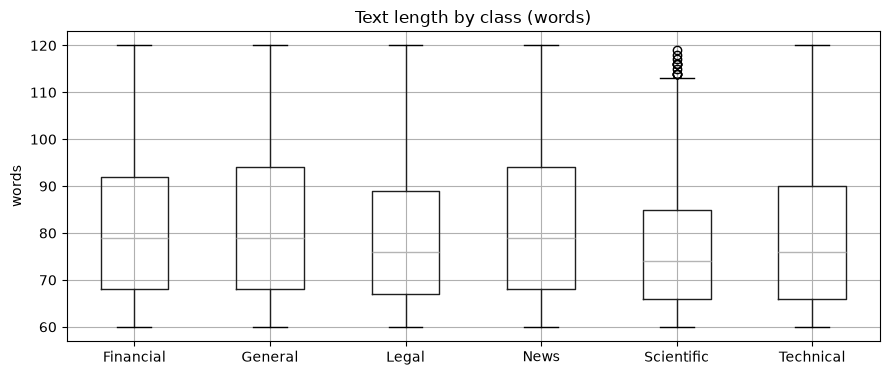

In [16]:
fig, ax = plt.subplots(figsize=(9, 4))
dataset.boxplot(column="n_words", by="label", ax=ax)
ax.set_title("Text length by class (words)")
ax.set_xlabel("")
ax.set_ylabel("words")
plt.suptitle("")
plt.tight_layout()
plt.show()

### Проверка на остатки мусора

Ищем шаблоны, которые должны были исчезнуть после очистки. Все счётчики должны быть 0 (или почти 0).

Знак `$` сам по себе — не мусор: в отчётах и новостях это суммы денег («$5 million»),
в Technical — переменные shell (`$PATH`). Это естественные признаки текстов, их оставляем.

In [17]:
leak_patterns = {
    "(CNN) --": r"\(CNN\)\s*--",
    "Watch ... »": "»",
    "iReport.com": r"iReport\.com",
    "userNNN:": r"\buser\d+:",
    "URL": r"https?://",
    "ITEM 7. heading": r"^ITEM\s*\d",
}
leaks = pd.Series(
    {
        name: dataset["text"].str.contains(p, regex=True).sum()
        for name, p in leak_patterns.items()
    }
)

# "$...$" in Financial/News is money ("$5 million and $3 million"), not LaTeX,
# so formulas are checked only where they could come from: Scientific
sci = dataset["label"] == "Scientific"
leaks["LaTeX in Scientific"] = (
    dataset.loc[sci, "text"].str.contains(r"\$[^$]+\$", regex=True).sum()
)
leaks

(CNN) --               0
Watch ... »            0
iReport.com            1
userNNN:               0
URL                    0
ITEM 7. heading        0
LaTeX in Scientific    0
dtype: int64

In [18]:
# One random example per class — read them with your own eyes
for label, group in dataset.groupby("label"):
    print(f"=== {label} ===")
    print(group["text"].iloc[0], end="\n\n")

=== Financial ===
Our business is subject to significant risks. You should carefully consider the risks described below and the other information in this Annual Report, including our financial statements and related notes, before you decide to invest in our Common Stock. If any of the following risks or uncertainties actually occur, our business, results of operations or financial condition could be materially harmed, the trading price of our Common Stock could decline and you could

=== General ===
Among the first modern motorways in the Czech Republic was the motorway from Prague to the Slovak border through Brno whose construction was started on May 2, 1939. Motorways are dual carriageways with tolls and a speed limit of 130 km/h. Highways can be single and dual carriageway with a speed limit of 90 km/h (dual carriageways are commonly signposted as Roads for motorcars with a speed limit of 110 km/h). ŘSD currently manages and maintains 1,369 km of motorways (dálnice). Waterways The 

## 5. Сохранение

Формат **parquet**: хранит типы колонок, сжат, читается быстрее CSV.
Папка `data/` в `.gitignore` — датасет в git не попадает, его всегда можно пересобрать этим ноутбуком.

Колонку `n_words` не сохраняем — это служебная колонка для проверки, её легко посчитать заново.

In [19]:
OUT_PATH.parent.mkdir(parents=True, exist_ok=True)
dataset.drop(columns="n_words").to_parquet(OUT_PATH, index=False)

check = pd.read_parquet(OUT_PATH)
print(OUT_PATH, check.shape)
check.head()

D:\FinSight\data\processed\dataset.parquet (12000, 4)


,text,label,source,doc_id
0,Our business is subject to significant risks. ...,Financial,edgar_10k,edgar_10k:1045942_2020.htm
1,The decision came after the two sides met to r...,News,cnn_dailymail,cnn_dailymail:901a8addcf431f8a23b3c324bb85939e...
2,We believe our emphasis on product formats suc...,Financial,edgar_10k,edgar_10k:1702744_2020.htm
3,"These spectra, which occur only in the polariz...",Scientific,arxiv,arxiv:0704.3632
4,During the early part of the first quarter of ...,Financial,edgar_10k,edgar_10k:882361_2020.htm
